<a href="https://colab.research.google.com/github/souha365/heart-failure-analysis/blob/main/notebooks/01_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Heart Failure: exploratory analysis
First look at the dataset: size, missing values, and the link between clinical variables and death.

In [2]:
import pandas as pd

url = "https://raw.githubusercontent.com/souha365/heart-failure-analysis/main/data/heart_failure_clinical_records_dataset.csv"
df = pd.read_csv(url)

df.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


In [2]:
df.shape


(299, 13)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  DEATH_EVENT               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 30.5 KB


In [4]:
df.isnull().sum()

,0
age,0
anaemia,0
creatinine_phosphokinase,0
diabetes,0
ejection_fraction,0
high_blood_pressure,0
platelets,0
serum_creatinine,0
serum_sodium,0
sex,0


In [5]:
df["DEATH_EVENT"].value_counts()

,count
DEATH_EVENT,
0,203
1,96


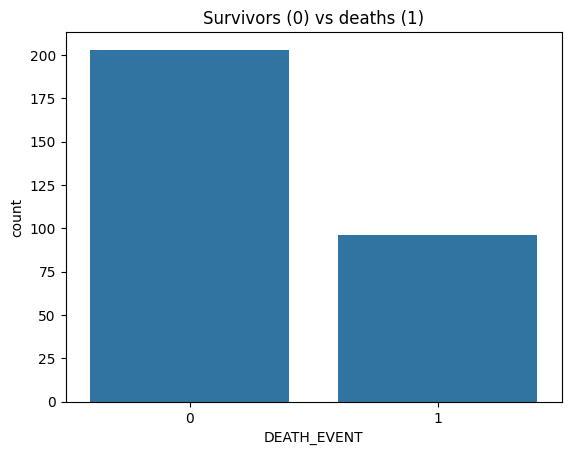

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="DEATH_EVENT")
plt.title("Survivors (0) vs deaths (1)")
plt.show()

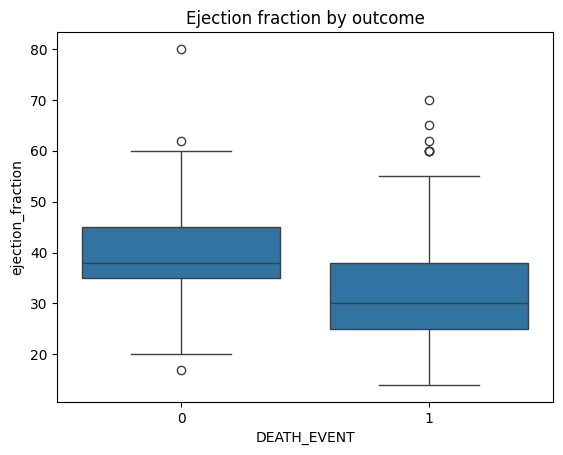

In [16]:
sns.boxplot(data=df, x="DEATH_EVENT", y="ejection_fraction")
plt.title("Ejection fraction by outcome")
plt.savefig("ejection_fraction.png", dpi=150, bbox_inches="tight")
plt.show()

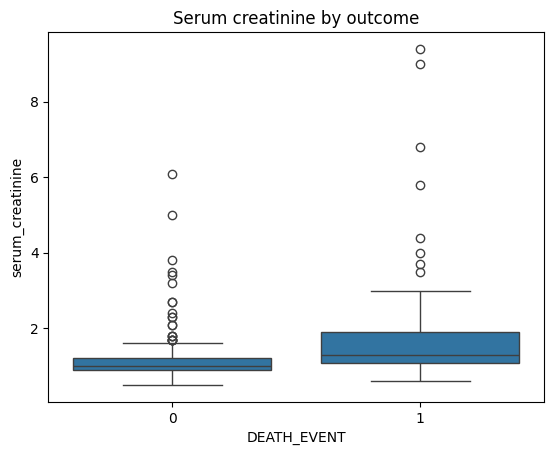

In [15]:
sns.boxplot(data=df, x="DEATH_EVENT", y="serum_creatinine")
plt.title("Serum creatinine by outcome")
plt.savefig("serum_creatinine.png", dpi=150, bbox_inches="tight")
plt.show()

In [3]:
X = df.drop(columns=["DEATH_EVENT", "time"])
y = df["DEATH_EVENT"]

print(X.shape)
print(y.shape)

(299, 11)
(299,)


In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)

(239, 11) (60, 11)


In [5]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(n_estimators=200, random_state=42)
model.fit(X_train, y_train)

RandomForestClassifier(n_estimators=200, random_state=42)

In [6]:
from sklearn.metrics import accuracy_score

y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.7333333333333333


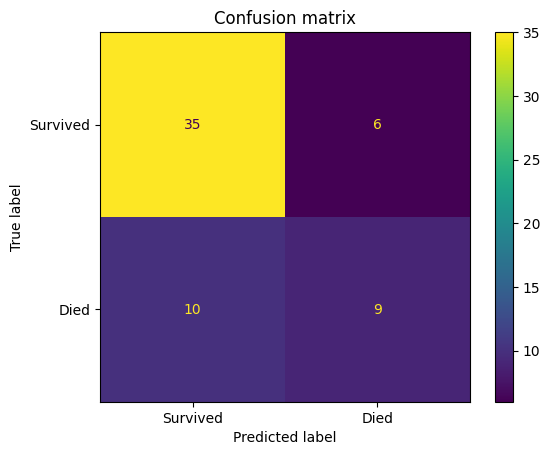

In [7]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["Survived", "Died"]).plot()
plt.title("Confusion matrix")
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, target_names=["Survived", "Died"]))

              precision    recall  f1-score   support

    Survived       0.78      0.85      0.81        41
        Died       0.60      0.47      0.53        19

    accuracy                           0.73        60
   macro avg       0.69      0.66      0.67        60
weighted avg       0.72      0.73      0.72        60



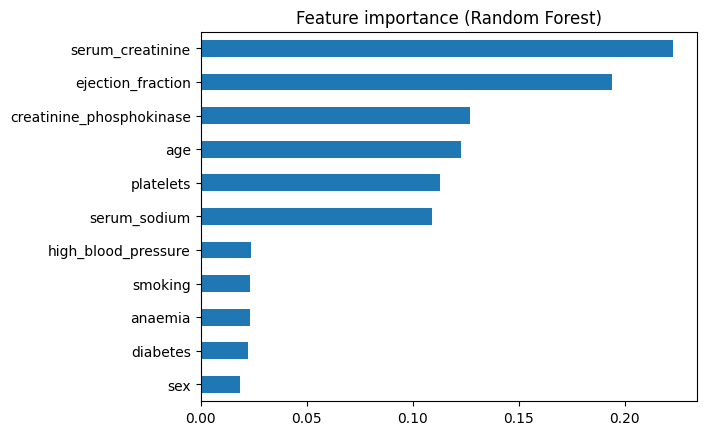

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

importances = pd.Series(model.feature_importances_, index=X.columns).sort_values()

importances.plot(kind="barh")
plt.title("Feature importance (Random Forest)")
plt.savefig("feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000)),
    "Random Forest (balanced)": RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, m in models.items():
    s = cross_validate(m, X_train, y_train, cv=cv, scoring=["roc_auc", "recall", "accuracy"])
    print(f"{name}: AUC={s['test_roc_auc'].mean():.2f}, recall={s['test_recall'].mean():.2f}, accuracy={s['test_accuracy'].mean():.2f}")

Logistic Regression: AUC=0.80, recall=0.75, accuracy=0.76
Random Forest (balanced): AUC=0.77, recall=0.42, accuracy=0.74
Gradient Boosting: AUC=0.71, recall=0.48, accuracy=0.69


              precision    recall  f1-score   support

    Survived       0.78      0.78      0.78        41
        Died       0.53      0.53      0.53        19

    accuracy                           0.70        60
   macro avg       0.65      0.65      0.65        60
weighted avg       0.70      0.70      0.70        60

AUC: 0.73


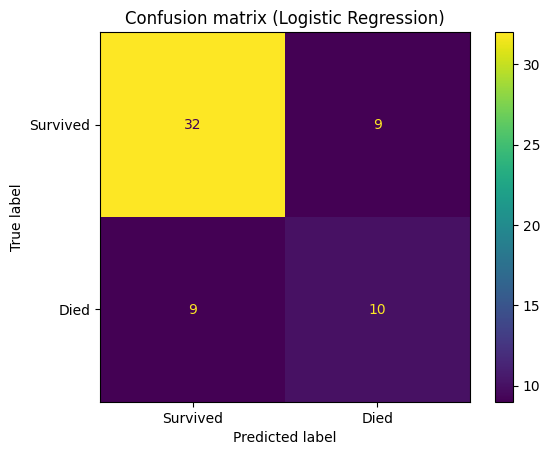

In [11]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score
import matplotlib.pyplot as plt

final_model = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000))
final_model.fit(X_train, y_train)

y_pred_lr = final_model.predict(X_test)
y_proba_lr = final_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_lr, target_names=["Survived", "Died"]))
print("AUC:", round(roc_auc_score(y_test, y_proba_lr), 2))

cm = confusion_matrix(y_test, y_pred_lr)
ConfusionMatrixDisplay(cm, display_labels=["Survived", "Died"]).plot()
plt.title("Confusion matrix (Logistic Regression)")
plt.savefig("confusion_matrix_lr.png", dpi=150, bbox_inches="tight")
plt.show()

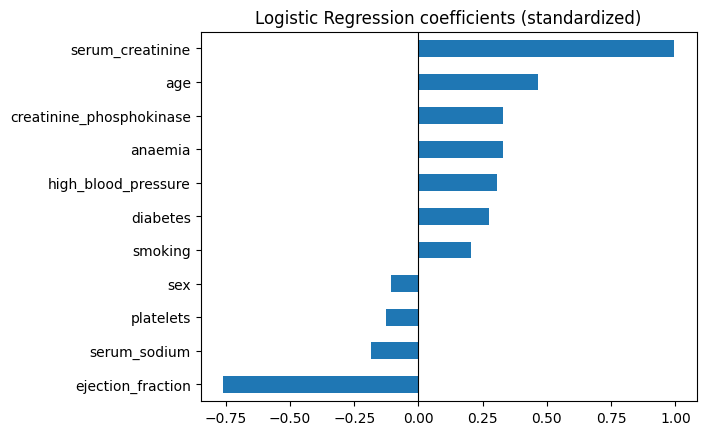

In [12]:
coefs = pd.Series(final_model[-1].coef_[0], index=X.columns).sort_values()

coefs.plot(kind="barh")
plt.title("Logistic Regression coefficients (standardized)")
plt.axvline(0, color="black", linewidth=0.8)
plt.savefig("lr_coefficients.png", dpi=150, bbox_inches="tight")
plt.show()